# 02 — Exploratory Data Analysis

Overall churn rate is 26.5%. This notebook asks: churn by *what* — which contract terms,
services, and payment methods are associated with customers leaving?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("../data/cleaned_telco_churn.csv")
print(df.shape)
print(f"Overall churn rate: {(df['Churn']=='Yes').mean():.1%}")


(7043, 21)
Overall churn rate: 26.5%


## Churn by contract type

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


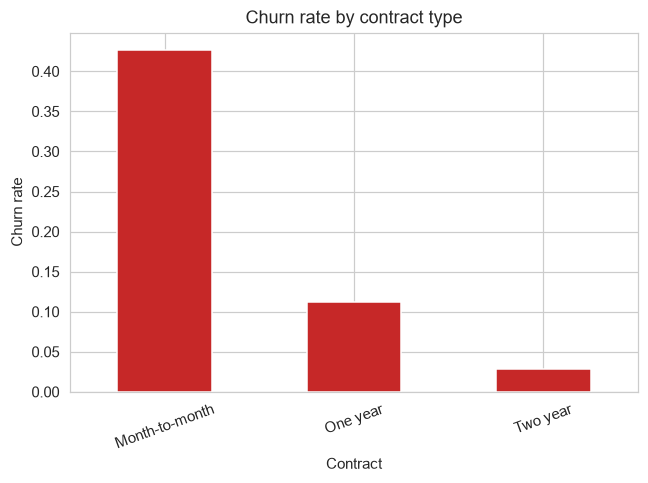

In [2]:
churn_by_contract = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
print(churn_by_contract.round(3))

fig, ax = plt.subplots(figsize=(6, 4.5))
churn_by_contract.plot.bar(ax=ax, color="#C62828")
ax.set_ylabel("Churn rate")
ax.set_title("Churn rate by contract type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../images/churn_by_contract.png", dpi=130, bbox_inches="tight")
plt.show()


**Month-to-month customers churn at 42.7%, vs. 11.3% for one-year and just 2.8% for two-year
contracts** — a 15x gap between the extremes. Contract length is the single strongest lever in
this dataset for reducing churn.

## Churn by internet service and payment method

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn, dtype: float64
PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: Churn, dtype: float64


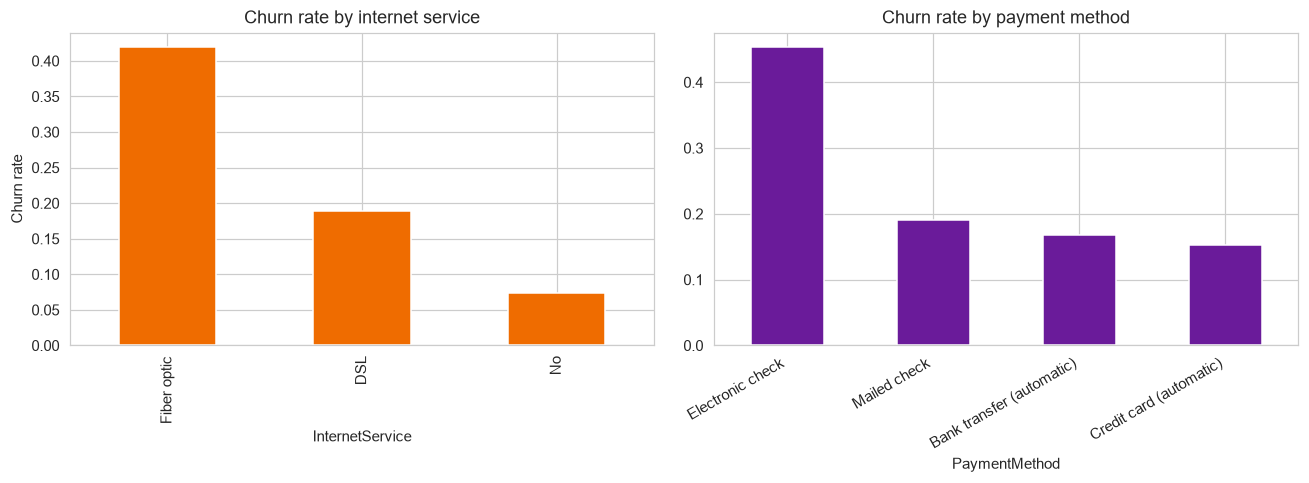

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

churn_by_internet = df.groupby("InternetService")["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
churn_by_internet.plot.bar(ax=axes[0], color="#EF6C00")
axes[0].set_title("Churn rate by internet service")
axes[0].set_ylabel("Churn rate")

churn_by_payment = df.groupby("PaymentMethod")["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
churn_by_payment.plot.bar(ax=axes[1], color="#6A1B9A")
axes[1].set_title("Churn rate by payment method")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../images/churn_by_service_payment.png", dpi=130, bbox_inches="tight")
plt.show()

print(churn_by_internet.round(3))
print(churn_by_payment.round(3))


**Fiber optic customers churn at 41.9% vs. 19.0% for DSL** — worth investigating whether this
is a price sensitivity issue (fiber is the pricier tier) or a service-quality issue, since this
dataset alone can't distinguish the two. **Electronic check payers churn at 45.3%**, more than
double every other payment method — a strong, actionable signal for the billing team.

## Tenure and monthly charges: churners vs. retained customers

       tenure  MonthlyCharges
Churn                        
No      37.57           61.27
Yes     17.98           74.44


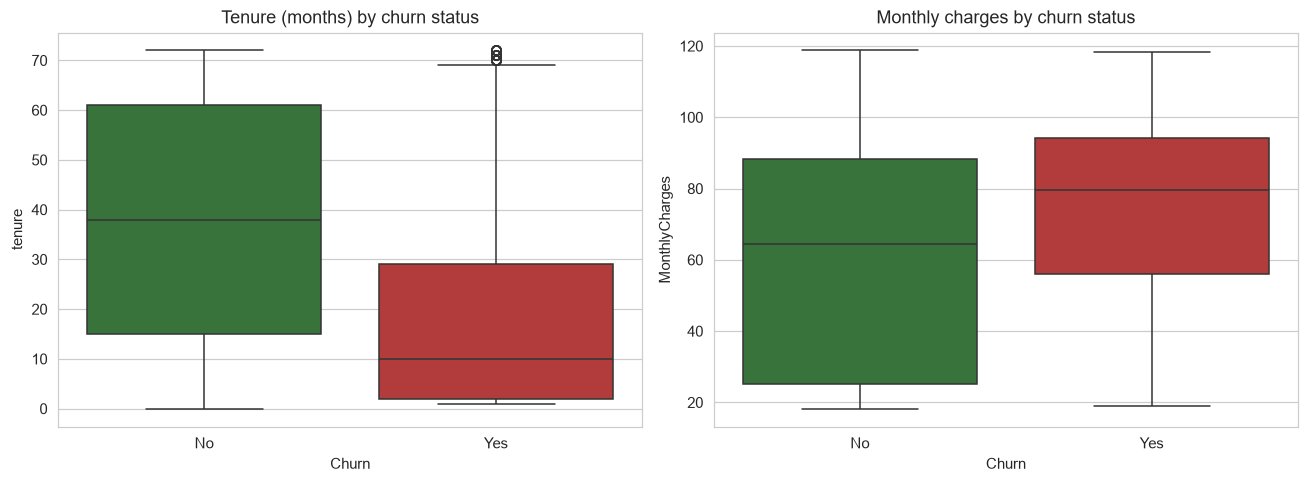

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0], palette=["#2E7D32", "#C62828"], hue="Churn", legend=False)
axes[0].set_title("Tenure (months) by churn status")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1], palette=["#2E7D32", "#C62828"], hue="Churn", legend=False)
axes[1].set_title("Monthly charges by churn status")

plt.tight_layout()
plt.savefig("../images/tenure_charges_by_churn.png", dpi=130, bbox_inches="tight")
plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(2))


Churners have less than half the average tenure of retained customers (18.0 vs. 37.6 months)
and pay more per month on average ($74.44 vs. $61.27) — consistent with the contract-length
finding: newer, higher-paying, shorter-commitment customers are the highest-risk segment.

## Correlation structure of numeric features

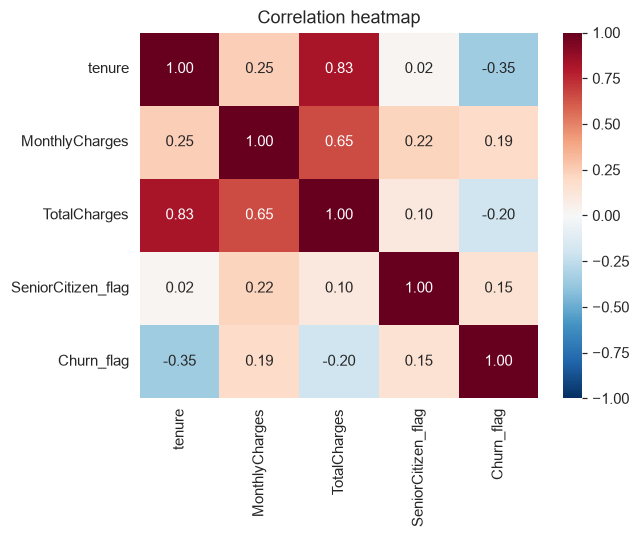

In [5]:
numeric_df = df.copy()
numeric_df["Churn_flag"] = (numeric_df["Churn"] == "Yes").astype(int)
numeric_df["SeniorCitizen_flag"] = (numeric_df["SeniorCitizen"] == "Yes").astype(int)
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen_flag", "Churn_flag"]
corr = numeric_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, vmin=-1, vmax=1)
ax.set_title("Correlation heatmap")
plt.tight_layout()
plt.savefig("../images/correlation_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()


`tenure` has the strongest correlation with churn (r=-0.35) of the numeric features — longer
tenure, lower churn. `MonthlyCharges` correlates positively (r=0.19), consistent with the boxplot
above. `TotalCharges` correlates negatively (r=-0.20), but that's largely a byproduct of it being
tenure × monthly charges, not an independent signal.

## EDA takeaways carried into the ML notebook

1. Contract length is the dominant churn driver — month-to-month customers churn 15x more
   than two-year customers.
2. Fiber optic and electronic-check payment are both associated with churn rates roughly double
   the dataset average.
3. Churners are newer (18.0 vs. 37.6 months tenure) and pay more per month ($74.44 vs. $61.27).
4. Class balance (26.5% churn) is reasonable for classification — unlike some imbalanced-label
   problems, this dataset should support a genuinely useful classifier, tested next.
